In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from preprocessing import crop_frame, octagon_mask, run_out_of_body_detector_pipeline

In [7]:
def laplacian_on_kept(oob_result, mask, downscale=2):
    """Blur score for the frames kept by the out-of-body detector only.
    Each cropped grayscale frame is shrunk by `downscale` (INTER_AREA averages
    each 2x2 block, removing pixel-level noise and compression artefacts),
    then score = variance of the Laplacian inside the (shrunk) octagon mask.
    Low = blurry. Returns (kept_idx, scores): frame numbers and scores, same order."""
    h, w = mask.shape
    size = (w // downscale, h // downscale)                       # (675, 540) for downscale=2
    small_mask = cv2.resize(mask.astype(np.uint8), size, interpolation=cv2.INTER_NEAREST)
    small_mask = cv2.erode(small_mask, np.ones((3, 3), np.uint8)).astype(bool)   # keep the border margin at the smaller size

    kept_idx = np.array(sorted(i for s in oob_result["kept"] for i in range(s["start"], s["end"])))
    wanted = set(kept_idx.tolist())
    scores = {}
    cap = cv2.VideoCapture(oob_result["video_path"])
    i = 0
    while len(scores) < len(wanted):
        if i in wanted:
            ret, frame = cap.read()
            if not ret:
                break
            g = cv2.cvtColor(crop_frame(frame), cv2.COLOR_BGR2GRAY)
            g = cv2.resize(g, size, interpolation=cv2.INTER_AREA)  # half resolution
            lap = cv2.Laplacian(g, cv2.CV_64F)                    # default 3x3 kernel
            scores[i] = float(lap[small_mask].var())
        else:
            if not cap.grab():
                break
        i += 1
    cap.release()
    return kept_idx, np.array([scores.get(i, np.nan) for i in kept_idx])

In [3]:
def read_frames_at(video_path, indices):
    """Read specific frames by sequential decoding (exact indices). Returns {index: cropped BGR frame}."""
    wanted = set(int(i) for i in indices)
    out, i = {}, 0
    cap = cv2.VideoCapture(video_path)
    while wanted - out.keys():
        ret, frame = cap.read()
        if not ret:
            break
        if i in wanted:
            out[i] = crop_frame(frame)
        i += 1
    cap.release()
    return out


def contiguous_runs(idx):
    """Turn sorted frame indices into (start, end_exclusive) runs, for shading."""
    runs, start, prev = [], idx[0], idx[0]
    for i in idx[1:]:
        if i != prev + 1:
            runs.append((start, prev + 1)); start = i
        prev = i
    runs.append((start, prev + 1))
    return runs


def plot_sharpness(title, kept_idx, scores, cut_pcts=(10, 20), ax=None):
    """Blur score of the kept frames at their frame number, one line per kept segment,
    with the percentile cut-offs (computed over the kept frames)."""
    cuts = {p: np.percentile(scores, p) for p in cut_pcts}
    pos = {f: k for k, f in enumerate(kept_idx)}
    for s0, s1 in contiguous_runs(kept_idx):
        ax.axvspan(s0, s1, color="green", alpha=0.12)
        seg = [pos[f] for f in range(s0, s1)]
        ax.plot(kept_idx[seg], scores[seg], linewidth=0.8, color="tab:blue")
    colors = {cut_pcts[0]: "red", cut_pcts[-1]: "orange"}
    for p, c in cuts.items():
        ax.axhline(c, color=colors.get(p, "red"), linestyle="--", linewidth=1,
                   label=f"{p}th pct = {c:.1f}")
    below = scores < cuts[cut_pcts[-1]]
    ax.scatter(kept_idx[below], scores[below], s=6, color="red", zorder=3,
               label=f"frames below {cut_pcts[-1]}th pct")
    ax.set_title(title)
    ax.set_xlabel("frame index")
    ax.set_ylabel("Laplacian variance (masked)")
    ax.legend(loc="upper right", fontsize=8)
    return cuts

In [25]:
video_path = r"C:\Users\ahmed\Documents\Jobs\Klinikum Oldenburg\Selected_videos\OA245A0_05-05-26_102303.mp4"

r = run_out_of_body_detector_pipeline(video_path, plot=False)

mask = octagon_mask()

frames analyzed: 1295  |  min=63.9  max=156.9  mean=110.2
All segments:
     0-414  len=414  mean= 124.2 range_90_10=  4.9
   414-475  len=61   mean= 130.7 range_90_10=  2.3
   475-612  len=137  mean= 123.5 range_90_10=  2.0
   612-685  len=73   mean= 119.4 range_90_10=  4.3
   685-721  len=36   mean= 126.2 range_90_10= 19.3
   721-777  len=56   mean= 113.0 range_90_10= 13.2
   777-807  len=30   mean=  78.9 range_90_10= 32.8
   807-845  len=38   mean=  97.6 range_90_10= 25.7
   845-875  len=30   mean= 130.2 range_90_10= 39.8
   875-919  len=44   mean= 111.1 range_90_10= 37.5
   919-1009 len=90   mean=  89.4 range_90_10=  7.5
  1009-1164 len=155  mean=  85.0 range_90_10=  4.2
  1164-1295 len=131  mean=  81.7 range_90_10=  3.2

Survivors (range_90_10<=10):
     0-414  len=414  mean= 124.2 range_90_10=  4.9
   414-475  len=61   mean= 130.7 range_90_10=  2.3
   475-612  len=137  mean= 123.5 range_90_10=  2.0
   612-685  len=73   mean= 119.4 range_90_10=  4.3
   919-1009 len=90   mean=  89.


kept frames scored: 551   (NaN: 0)


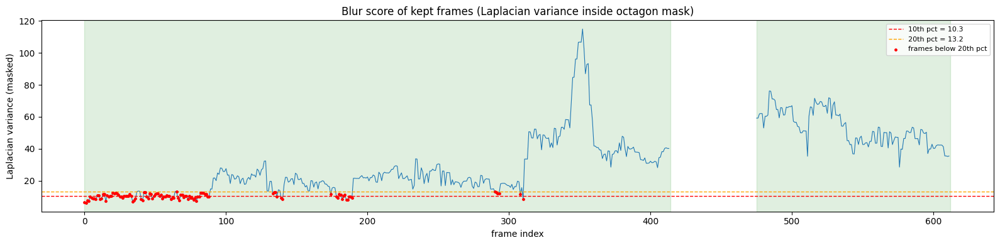

In [26]:
kept_idx, lap_scores = laplacian_on_kept(r, mask)
print(f"\nkept frames scored: {len(lap_scores)}   (NaN: {int(np.isnan(lap_scores).sum())})")

fig, ax = plt.subplots(figsize=(16, 4))
cuts = plot_sharpness("Blur score of kept frames (Laplacian variance inside octagon mask)",
                      kept_idx, lap_scores, ax=ax)
plt.tight_layout(); plt.show()

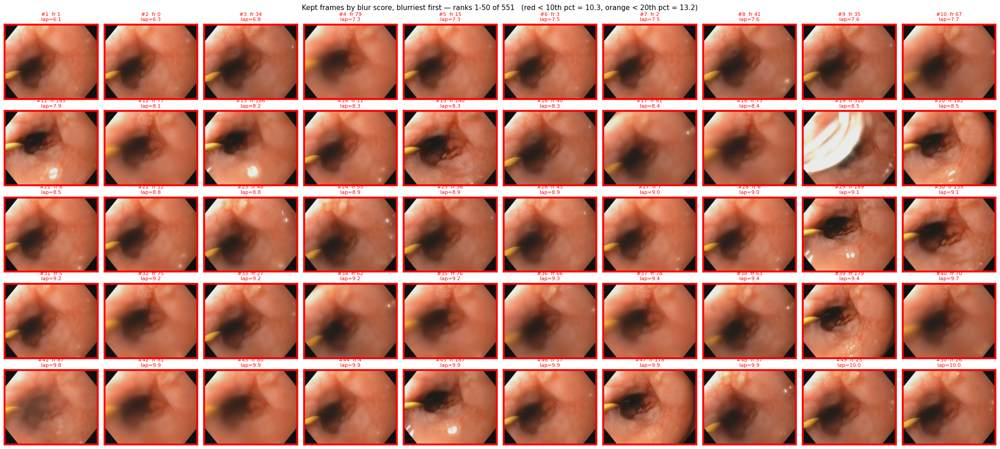

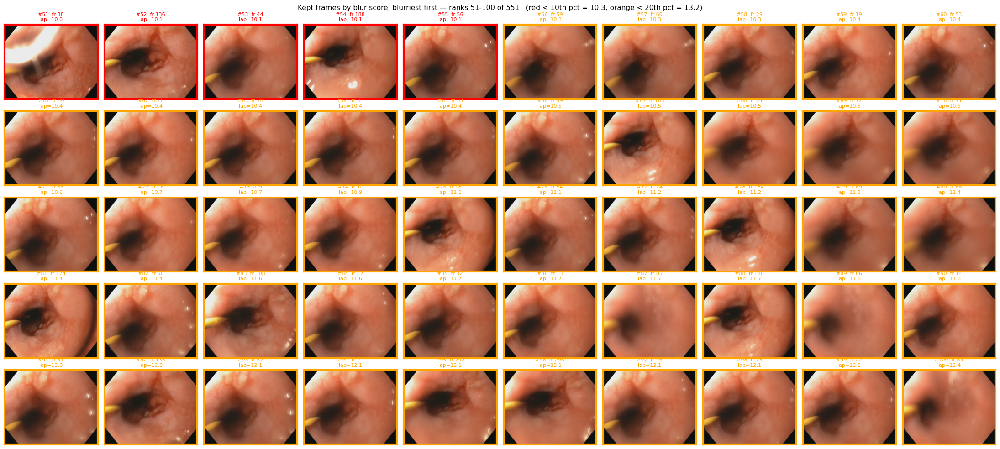

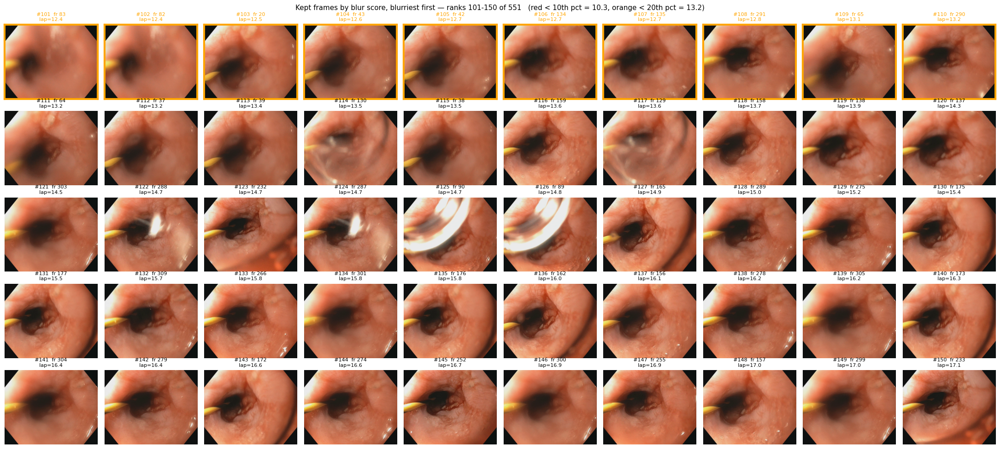

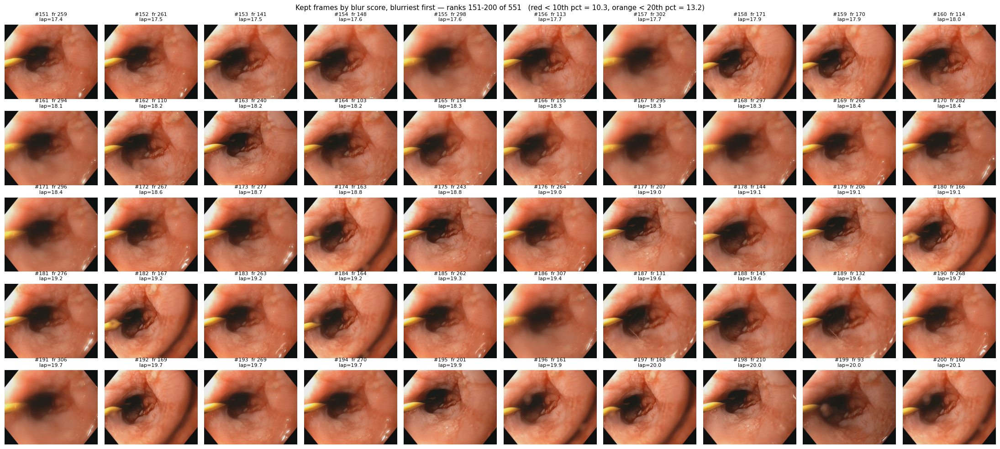

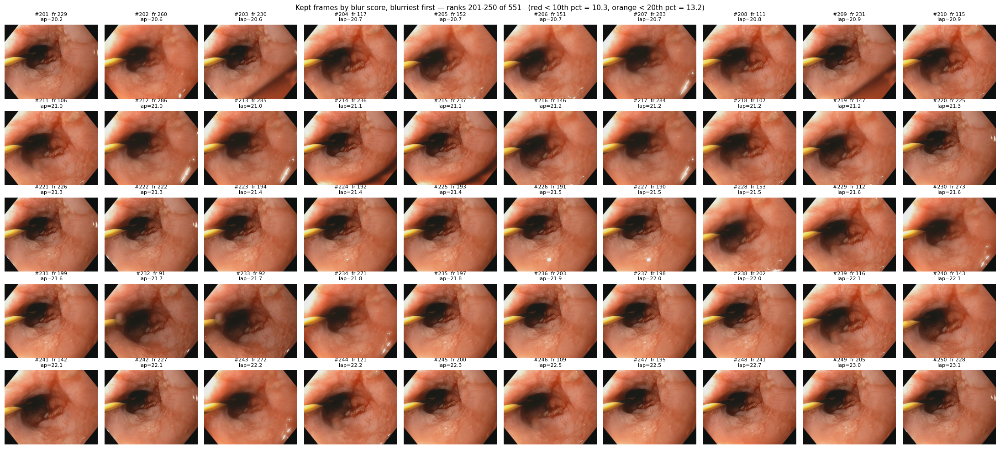

...

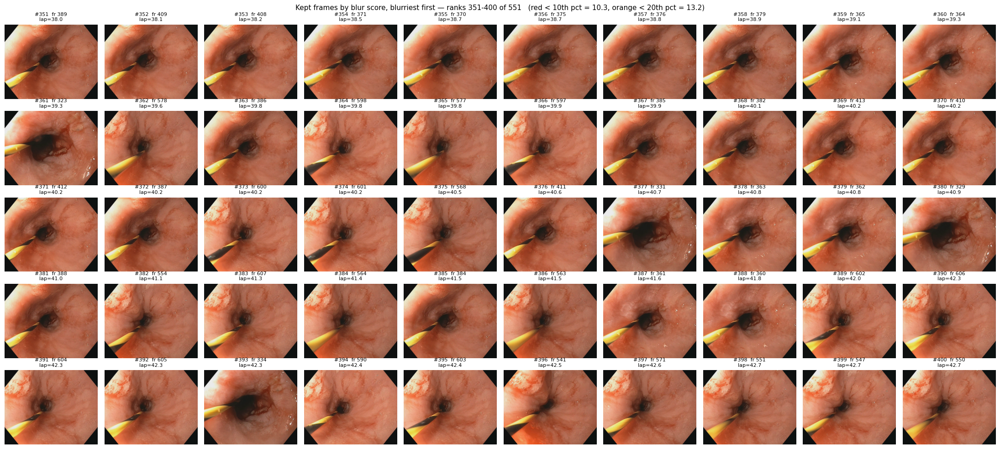

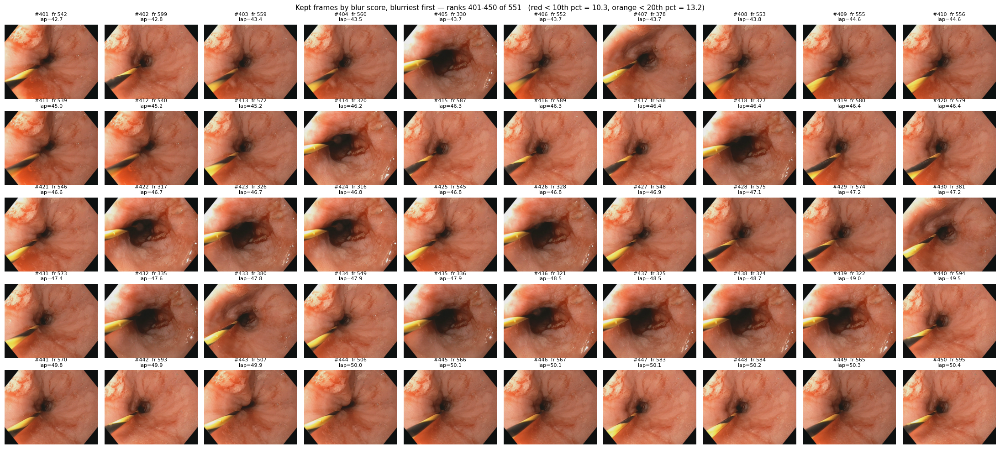

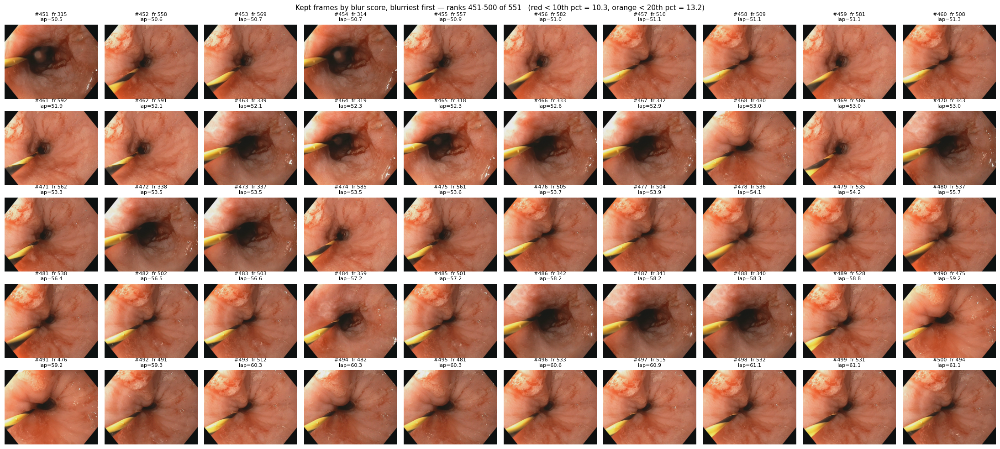

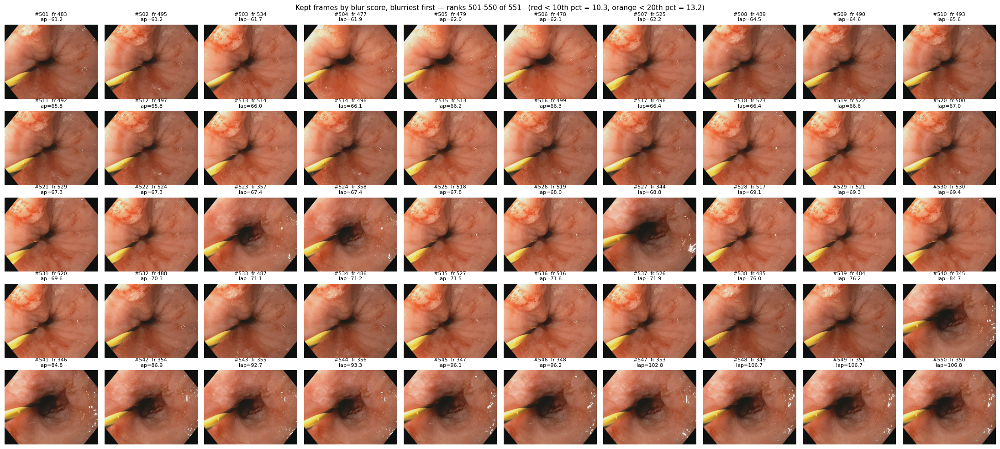

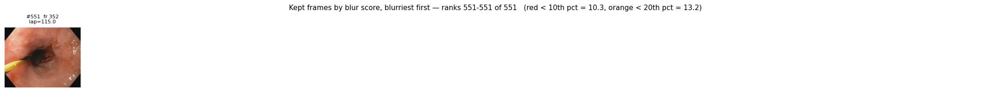

In [27]:
def read_thumbnails(video_path, indices, width=270):
    """Read the given frames (cropped) and shrink each to `width` px wide. Returns {index: RGB thumbnail}."""
    wanted = set(int(i) for i in indices)
    out, i = {}, 0
    cap = cv2.VideoCapture(video_path)
    while wanted - out.keys():
        if i in wanted:
            ret, frame = cap.read()
            if not ret:
                break
            c = crop_frame(frame)
            h = int(c.shape[0] * width / c.shape[1])
            out[i] = cv2.cvtColor(cv2.resize(c, (width, h), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB)
        elif not cap.grab():
            break
        i += 1
    cap.release()
    return out


def show_by_blurriness(kept_idx, scores, thumbs, cuts, per_page=50, cols=10):
    """All kept frames sorted blurriest -> sharpest, in pages of `per_page`.
    Title: rank, frame number, score. Red frame = below 10th pct, orange = below 20th pct."""
    order = np.argsort(scores)
    p10, p20 = cuts[10], cuts[20]
    for start in range(0, len(order), per_page):
        page = order[start:start + per_page]
        rows = int(np.ceil(len(page) / cols))
        fig, axes = plt.subplots(rows, cols, figsize=(2.2 * cols, 2.0 * rows))
        axes = np.atleast_2d(axes)
        for k, ax in enumerate(axes.flat):
            ax.axis("off")
            if k >= len(page):
                continue
            j = page[k]
            f, s = int(kept_idx[j]), scores[j]
            ax.imshow(thumbs[f])
            color = "red" if s < p10 else "orange" if s < p20 else "black"
            ax.set_title(f"#{start + k + 1}  fr {f}\nlap={s:.1f}", fontsize=8, color=color)
            if color != "black":
                for side in ax.spines.values():
                    side.set_visible(True); side.set_color(color); side.set_linewidth(3)
                ax.axis("on"); ax.set_xticks([]); ax.set_yticks([])
        fig.suptitle(f"Kept frames by blur score, blurriest first — ranks {start + 1}-{start + len(page)} of {len(order)}"
                     f"   (red < 10th pct = {p10:.1f}, orange < 20th pct = {p20:.1f})", fontsize=11)
        plt.tight_layout(); plt.show()


thumbs = read_thumbnails(r["video_path"], kept_idx)
show_by_blurriness(kept_idx, lap_scores, thumbs, cuts)

In [1]:
video_path = r"C:\Users\ahmed\Documents\Jobs\Klinikum Oldenburg\Selected_videos\OA245A0_05-05-26_102303.mp4"

In [2]:
from preprocessing import main
res = main(video_path)              # or main(video_path, plot=True)

frames analyzed: 1295  |  min=63.9  max=156.9  mean=110.2
All segments:
     0-414  len=414  mean= 124.2 range_90_10=  4.9
   414-475  len=61   mean= 130.7 range_90_10=  2.3
   475-612  len=137  mean= 123.5 range_90_10=  2.0
   612-685  len=73   mean= 119.4 range_90_10=  4.3
   685-721  len=36   mean= 126.2 range_90_10= 19.3
   721-777  len=56   mean= 113.0 range_90_10= 13.2
   777-807  len=30   mean=  78.9 range_90_10= 32.8
   807-845  len=38   mean=  97.6 range_90_10= 25.7
   845-875  len=30   mean= 130.2 range_90_10= 39.8
   875-919  len=44   mean= 111.1 range_90_10= 37.5
   919-1009 len=90   mean=  89.4 range_90_10=  7.5
  1009-1164 len=155  mean=  85.0 range_90_10=  4.2
  1164-1295 len=131  mean=  81.7 range_90_10=  3.2

Survivors (range_90_10<=10):
     0-414  len=414  mean= 124.2 range_90_10=  4.9
   414-475  len=61   mean= 130.7 range_90_10=  2.3
   475-612  len=137  mean= 123.5 range_90_10=  2.0
   612-685  len=73   mean= 119.4 range_90_10=  4.3
   919-1009 len=90   mean=  89.

In [6]:
res['blur']['scores']

{0: 6.321724464127273,
 1: 6.143974744495757,
 2: 7.505855969183109,
 3: 7.468029756196998,
 4: 9.899178544610647,
 5: 9.159336476490072,
 6: 9.046345951901316,
 7: 8.982985661204829,
 8: 8.544073937831644,
 9: 10.732443635533722,
 10: 10.919983942342494,
 11: 8.279440590492584,
 12: 8.80059241509642,
 13: 11.695458095093453,
 14: 11.80011711851715,
 15: 7.329293965723369,
 16: 10.687296805953372,
 17: 9.91164944576706,
 18: 10.404793485185234,
 19: 10.376991554105622,
 20: 12.46412972110159,
 21: 12.105909931279701,
 22: 12.246312891005694,
 23: 12.120906484648067,
 24: 11.160711259446009,
 25: 9.957619195626574,
 26: 9.963416830985766,
 27: 9.225180753010534,
 28: 10.415970943201085,
 29: 10.328943651048954,
 30: 10.401797871414377,
 31: 10.436409986314516,
 32: 11.675031999133324,
 33: 10.448214510465064,
 34: 6.826144212530328,
 35: 7.63794971097169,
 36: 8.881542217069413,
 37: 13.246274787317878,
 38: 13.525177504566106,
 39: 13.427078266482521,
 40: 8.340589379972739,
 41: 7.569